In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler


1. Statistical Analysis

In [2]:
data_path = "Chico_CA_2020_2024.csv"
# read the csv file into Dataframe
df = pd.read_csv(data_path)
print("Initial shape:", df.shape)
df.head()   #display 5rows

Initial shape: (1827, 11)


,Date,Overall AQI Value,Main Pollutant,Site Name (of Overall AQI),Site ID (of Overall AQI),Source (of Overall AQI),CO,Ozone,PM10,PM25,NO2
0,1/1/2020,85,PM2.5,"TRAFFIC, RURAL PAVED ROAD",06-007-4001,AQS,6,28,25,85,19
1,1/2/2020,66,PM2.5,Chico-East Avenue,06-007-0008,AQS,7,33,20,66,17
2,1/3/2020,77,PM2.5,Chico-East Avenue,06-007-0008,AQS,8,31,28,77,20
3,1/4/2020,67,PM2.5,"TRAFFIC, RURAL PAVED ROAD",06-007-4001,AQS,6,30,16,67,16
4,1/5/2020,64,PM2.5,Chico-East Avenue,06-007-0008,AQS,6,32,17,64,17


In [3]:
# Inspect missing values
print("Missing Values (%):")
print(df.isna().mean().sort_values(ascending=False) * 100)

Missing Values (%):
Date                          0.0
Overall AQI Value             0.0
Main Pollutant                0.0
Site Name (of Overall AQI)    0.0
Site ID (of Overall AQI)      0.0
Source (of Overall AQI)       0.0
CO                            0.0
Ozone                         0.0
PM10                          0.0
PM25                          0.0
NO2                           0.0
dtype: float64


2. DATA Preprocessing Steps

In [4]:
# Define the path and the columns of interest for reuse
DATA_PATH = "Chico_CA_2020_2024.csv"
NUMERIC_COLS = ['Overall AQI Value', 'CO', 'Ozone', 'PM10', 'PM25', 'NO2']
COLS_TO_KEEP = ['Date'] + NUMERIC_COLS
NON_NUMERIC_COLS = [
    'Main Pollutant', 
    'Site Name (of Overall AQI)', 
    'Site ID (of Overall AQI)', 
    'Source (of Overall AQI)'
]

In [5]:
# 1. Convert 'Date' column into datetime format and set as index
df.index = pd.to_datetime(df['Date'])
# Drop original 'Date' column
df = df.drop('Date', axis=1)
df.head()

,Overall AQI Value,Main Pollutant,Site Name (of Overall AQI),Site ID (of Overall AQI),Source (of Overall AQI),CO,Ozone,PM10,PM25,NO2
Date,,,,,,,,,,
2020-01-01,85,PM2.5,"TRAFFIC, RURAL PAVED ROAD",06-007-4001,AQS,6,28,25,85,19
2020-01-02,66,PM2.5,Chico-East Avenue,06-007-0008,AQS,7,33,20,66,17
2020-01-03,77,PM2.5,Chico-East Avenue,06-007-0008,AQS,8,31,28,77,20
2020-01-04,67,PM2.5,"TRAFFIC, RURAL PAVED ROAD",06-007-4001,AQS,6,30,16,67,16
2020-01-05,64,PM2.5,Chico-East Avenue,06-007-0008,AQS,6,32,17,64,17


In [6]:
#2. Select only necessary column = Drop unnecessary column
df_cleaned = df[NUMERIC_COLS].copy()
df_cleaned.head()

,Overall AQI Value,CO,Ozone,PM10,PM25,NO2
Date,,,,,,
2020-01-01,85,6,28,25,85,19
2020-01-02,66,7,33,20,66,17
2020-01-03,77,8,31,28,77,20
2020-01-04,67,6,30,16,67,16
2020-01-05,64,6,32,17,64,17


In [7]:
#3. Handle Missing Values and Clean dataset
initial_shape = df_cleaned.shape

#a) Remove any rows where ALL numeric data is NaN.
df_cleaned.dropna(inplace=True)

#b) Convert columns to numeric, coerce errors to NaN
for col in NUMERIC_COLS:
    df_cleaned[col] = pd.to_numeric(df_cleaned[col], errors='coerce')

#c) fill any NULL value with last known number
df_cleaned.fillna(method='ffill', inplace=True)

#check any missing value
print("="*35)
print(f"Initial shape: {df.shape}")
print(f"Cleaned shape: {df_cleaned.shape}")
print("Missing values check after cleaning:")
print(df_cleaned.isna().sum())

Initial shape: (1827, 10)
Cleaned shape: (1827, 6)
Missing values check after cleaning:
Overall AQI Value    0
CO                   0
Ozone                0
PM10                 0
PM25                 0
NO2                  0
dtype: int64


C:\Users\User\AppData\Local\Temp\ipykernel_17832\2549651278.py:12: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_cleaned.fillna(method='ffill', inplace=True)


In [8]:
#save .csv file with Date and numeric columns
df_with_date = df_cleaned.reset_index()
df_with_date[COLS_TO_KEEP].to_csv('preprocessed_data_unscaled.csv', index=False)

3. Min-Max Scaler

In [9]:
df_scaled = df_cleaned.copy()
scaler = MinMaxScaler()
FEATURE_COLS = ['CO', 'Ozone', 'PM10', 'PM25', 'NO2']
#scale the selected numeric columns， which is the training features, 
df_scaled[FEATURE_COLS] = scaler.fit_transform(df_scaled[FEATURE_COLS])

In [10]:
#save .csv file with Date and numeric columns
df_with_date = df_scaled.reset_index()
df_with_date[COLS_TO_KEEP].to_csv('preprocessed_data_minmax_scaled.csv', index=False)

4. Finalize Result

In [11]:
#Summary Statistics
print("After Cleaning:")
print("Shape:", df.shape)
print(df.describe().T)


After Cleaning:
Shape: (1827, 10)
                    count       mean        std   min   25%   50%   75%    max
Overall AQI Value  1827.0  56.135194  27.955034  21.0  40.0  50.0  63.0  508.0
PM25               1827.0  46.985222  31.648091   4.0  27.5  44.0  57.0  508.0


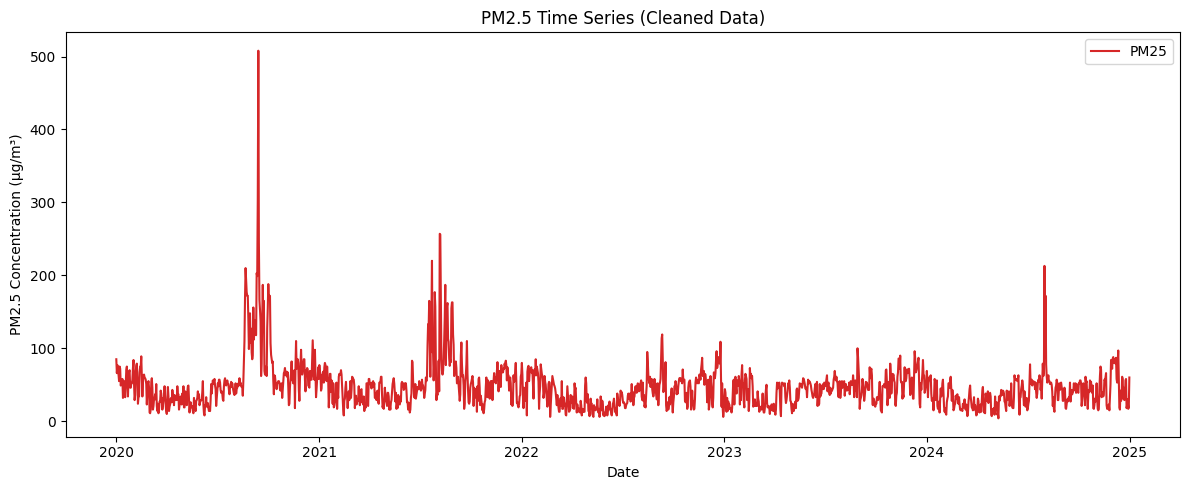

In [12]:
#Plot PM2.5 Trend
plt.figure(figsize=(12,5))
plt.plot(df_cleaned.index, df_cleaned['PM25'], color='tab:red', label='PM25')
plt.title("PM2.5 Time Series (Cleaned Data)")
plt.xlabel("Date")
plt.ylabel("PM2.5 Concentration (µg/m³)")
plt.legend()
plt.tight_layout()
plt.show()

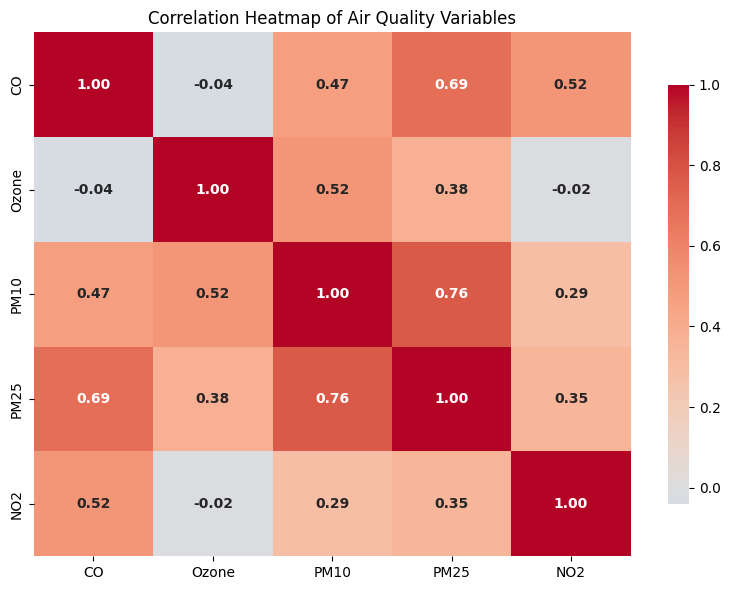

In [13]:
#Correlation Heatmap
plt.figure(figsize=(8,6))
sns.heatmap(df_cleaned[FEATURE_COLS].corr(), 
            cmap='coolwarm', 
            center=0, 
            annot=True,
            fmt='.2f',
            cbar_kws={'shrink': 0.8},
            annot_kws={'size': 10, 'weight': 'bold'})
plt.title("Correlation Heatmap of Air Quality Variables")
plt.tight_layout()
plt.show()